In [ ]:
import os
import numpy as np
from read_write_model import read_points3D_binary

# ====== 1. 读取 COLMAP 点云 ======
colmap_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0"
points_dict = read_points3D_binary(os.path.join(colmap_dir, "points3D.bin"))
points = np.array([v.xyz for v in points_dict.values()])  # (N,3)

# ====== 2. 点数驱动 Octree ======
import numpy as np
import torch

class OctreeNode:
    def __init__(self, center, size, points, depth=0):
        self.center = center   # cube 中心
        self.size = size       # cube 边长 (严格 1/2^depth)
        self.points = points
        self.children = []
        self.depth = depth

def build_octree(points, min_points=200, depth=0, center=None, root_size=None):
    points = np.asarray(points)

    # 初始化 root
    if depth == 0:
        mins, maxs = points.min(axis=0), points.max(axis=0)
        center = (mins + maxs) / 2
        root_size = np.max(maxs - mins)

    size = root_size / (2 ** depth)
    node = OctreeNode(center, size, points, depth)

    if len(points) <= min_points:
        return node

    # 子 cube 划分
    child_size = size / 2
    quarter = size / 4
    offsets = np.array([[dx, dy, dz] for dx in [-1, 1]
                                     for dy in [-1, 1]
                                     for dz in [-1, 1]]) * quarter
    for off in offsets:
        sub_center = center + off
        # 用严格区间避免边界点重复归属
        mask = np.all((points >= sub_center - child_size/2) & (points < sub_center + child_size/2), axis=1)
        if np.any(mask):
            child = build_octree(points[mask], min_points, depth+1, sub_center, root_size)
            node.children.append(child)

    return node


def collect_leaf_info(node, use_centroid=True):
    """收集所有 leaf 节点的 (位置, 半径)"""
    if not node.children:  # leaf
        pos = node.points.mean(axis=0) if use_centroid else node.center
        radius = node.size / 2 * np.sqrt(3)  # 半径为半对角线长度
        return [(pos, radius)]
    results = []
    for c in node.children:
        results.extend(collect_leaf_info(c, use_centroid))
    return results

def octree_sample(points, min_points=800, device="cpu"):
    """从点云中采样，返回 (positions, radii)"""
    root = build_octree(points, min_points=min_points)
    leaf_info = collect_leaf_info(root, use_centroid=True)

    positions = np.array([p for p, r in leaf_info])
    radii = np.array([r for p, r in leaf_info])

    positions = torch.from_numpy(positions).float().to(device)
    radii = torch.from_numpy(radii).float().to(device)

    return positions, radii

# ====== 3. 构建 Octree & 收集初始点 ======
leaf_positions, _ = octree_sample(points, min_points=800)

leaf_positions.shape

torch.Size([1020, 3])

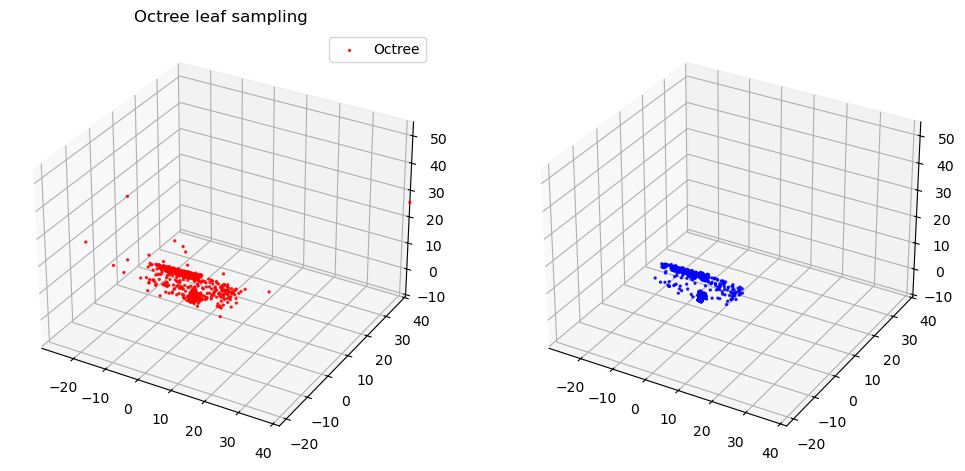

In [3]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 转 numpy
leaf_np = leaf_positions.detach().cpu().numpy() if not isinstance(leaf_positions, np.ndarray) else leaf_positions
rand_np = random_positions.detach().cpu().numpy() if not isinstance(random_positions, np.ndarray) else random_positions

# 统一坐标范围
mins = np.minimum(leaf_np.min(axis=0), rand_np.min(axis=0))
maxs = np.maximum(leaf_np.max(axis=0), rand_np.max(axis=0))

def set_axes_equal(ax, mins, maxs):
    ax.set_xlim(mins[0], maxs[0])
    ax.set_ylim(mins[1], maxs[1])
    ax.set_zlim(mins[2], maxs[2])

# 对比展示
fig = plt.figure(figsize=(12,6))

# Octree 采样
ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(leaf_np[:,0], leaf_np[:,1], leaf_np[:,2], 
            s=2, c="red", alpha=0.8, label="Octree")
set_axes_equal(ax1, mins, maxs)
ax1.set_title("Octree leaf sampling")
ax1.legend()

# 随机采样
ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(rand_np[:,0], rand_np[:,1], rand_np[:,2], 
            s=2, c="blue", alpha=0.8, label="Random")
set_axes_equal(ax2, mins, maxs)


In [ ]:
import os
import numpy as np
import open3d as o3d
from read_write_model import read_points3D_binary

colmap_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai/sparse/0"
points_dict = read_points3D_binary(os.path.join(colmap_dir, "points3D.bin"))

# 提取 xyz + rgb
points = np.array([p.xyz for p in points_dict.values()])
colors = np.array([p.rgb for p in points_dict.values()]) / 255.0  # 归一化到 [0,1]

# 构建 Open3D 点云对象
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

# 可视化
o3d.visualization.draw_geometries([pcd])
